# 09 · Clean B0: preparation, nested selection and OOF evaluation

EfficientNet-B0 starts from ImageNet features and learns a new melanoma output. The full bounded selection procedure repeats inside five preserved patient groups; the notebook explains preparation, learning, ranking, probability quality and decisions using saved clean records.

Read the stages in numerical order. Training uses separate, explicitly invoked runners; executing this notebook only loads development data and saved artifacts.

Original notebooks, images, checkpoints and results remain available. The reserved test is outside this workflow.

**Original methods and figure reference:** [09_image_b0_pilot.ipynb](../Subset/09_image_b0_pilot.ipynb), [14_image_nested_evaluation.ipynb](../Subset/14_image_nested_evaluation.ipynb). Read [method coverage](METHOD_COVERAGE.md) for retained methods and declared adaptations.

## Load the frozen clean development dataset

In [1]:
NOTEBOOK_STAGE = '09_image_modelling'
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from melanoma_detection.development_dataset import load_development_dataset, load_preserved_inner_memberships
from melanoma_detection.dedup_workflow import load_context, latest_evaluation, load_clean_scores, load_image_report, load_uncertainty_report, read_json, project_path, DIRECTORY, METADATA_SUITE, UNCERTAINTY
get_ipython().run_line_magic("matplotlib", "inline")
MANIFEST = "data/subset/processed/dedup_v1/dataset_manifest.json"
data, dataset_identity = load_development_dataset(ROOT, dataset_manifest=MANIFEST)
context = load_context(ROOT)
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
FIGURE_DIR = ROOT / DIRECTORY / "figures" / NOTEBOOK_STAGE
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def finish_figure(figure, filename):
    if not filename or Path(filename).name != filename:
        raise ValueError("Figure name must be a simple stem.")
    figure.savefig(FIGURE_DIR / (filename + ".png"), dpi=180, bbox_inches="tight")
    figure.savefig(FIGURE_DIR / (filename + ".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(figure)

_score_bundle = None
def score_bundle():
    global _score_bundle
    if _score_bundle is None:
        _score_bundle = load_clean_scores(ROOT)
    return _score_bundle
display(pd.DataFrame([{"Images": len(data), "Malignant images": int(data.target.sum()),
    "Patients": data.patient_id.nunique(), "Malignant patients": data.loc[data.target.eq(1), "patient_id"].nunique()}]))
display(Markdown("**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training."))

def show_saved_table(relative, limit=30):
    path = project_path(ROOT, relative)
    if not path.exists():
        display(Markdown("**Pending:** " + relative + ". No results are inferred from unfinished runs."))
        return pd.DataFrame()
    table = pd.read_csv(path)
    display(table.head(limit))
    if len(table) > limit:
        display(Markdown(f"Showing {limit} of {len(table)} rows; the complete CSV is saved."))
    return table

def comparison_table():
    evaluation = latest_evaluation(ROOT)
    if "output_directory" not in evaluation:
        display(Markdown("**Pending:** clean evaluation has not been generated."))
        return pd.DataFrame()
    path = project_path(ROOT, evaluation["output_directory"] + "/model_comparison.csv")
    return pd.read_csv(path)

def model_chart(table, title):
    if table.empty:
        display(Markdown("**Pending:** no verified scores are available for this stage."))
        return
    table = table.sort_values("average_precision")
    fig, ax = plt.subplots(figsize=(9, max(3.2, .38 * len(table) + 1.5)), layout="constrained")
    ax.barh(table.model, table.average_precision, color="#276b91")
    ax.set(title=title, xlabel="Unweighted mean outer-fold average precision", xlim=(0, max(.1, float(table.average_precision.max()) * 1.25)))
    finish_figure(fig, "model_comparison_ap")

def pilot_report(run_id):
    directory = ROOT / "results/image_d1_runs" / run_id
    path = directory / "summary.json"
    summary = read_json(path) if path.exists() else {"status": "pending"}
    if summary.get("status") == "complete":
        manifest = read_json(directory / "run_manifest.json")
        if manifest["dataset_identity"] != dataset_identity:
            raise ValueError("Pilot belongs to another dataset.")
        from melanoma_detection.development_dataset import sha256_file
        for relative, digest in summary["artifact_sha256"].items():
            artifact = (directory / relative).resolve()
            if not artifact.is_relative_to(directory.resolve()) or sha256_file(artifact) != digest:
                raise ValueError("Completed pilot artifact changed.")
    return directory, summary


,Images,Malignant images,Patients,Malignant patients
0,6706,127,422,88


**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training.

## Purpose, settings and the image pipeline

An architecture is the network design; a recipe fixes learning rate and weighting. An epoch is a pass through fitting images. Every distinct fitting job begins with original IMAGENET1K_V1 weights, a new classifier and fresh optimiser/scheduler. Dropout remains 0.2; batch-normalisation statistics stay frozen. The table records the exact 224-pixel weak-preparation settings.

,Setting,Value
0,architecture,efficientnet_b0
1,weights,IMAGENET1K_V1
2,image_size,224
3,dropout,0.2
4,augmentation,weak
5,preprocessing,none
6,microbatch,64
7,effective_batch,64
8,min_microbatch,4
9,head_lr,0.001


,id,backbone_lr,loss_weight
0,lr3e5_none,0.00003,none
1,lr1e4_none,0.00010,none
2,lr3e5_sqrt,0.00003,sqrt_ratio
3,lr1e4_sqrt,0.00010,sqrt_ratio


,Outer folds,Preserved inner folds,Screen epochs,Confirm epochs,Duration,Raw GPU fits,Calibration GPU fits,Fresh start
0,5,3,6,12,median of three saved AP-best epochs,35,15,IMAGENET1K_V1 for each distinct fit


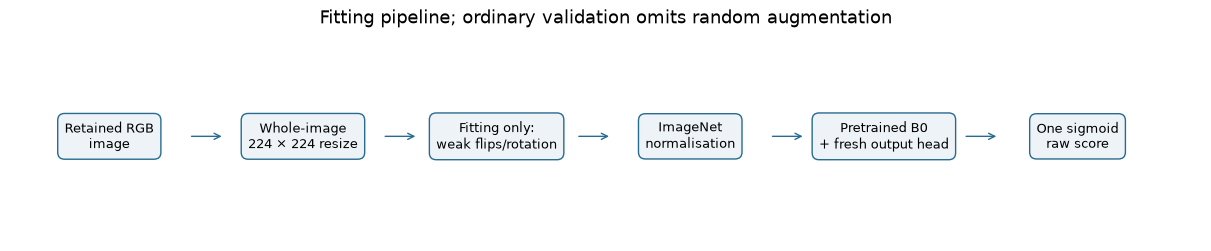

In [2]:
from melanoma_detection import dedup_notebook_images as image_docs
image_docs.image_settings(ROOT)
image_docs.show_pipeline(finish_figure)

## Inspect preserved fitting preparation

Read each row from original RGB through the deterministic validation view and three seeded weak fitting variants. Whole-image bilinear resize and ImageNet colour normalisation are shared. Flips/rotation occur only during fitting. These examples come from retained fitting patients in outer pool 0, inner fitting set; no model is trained and no source image changes.

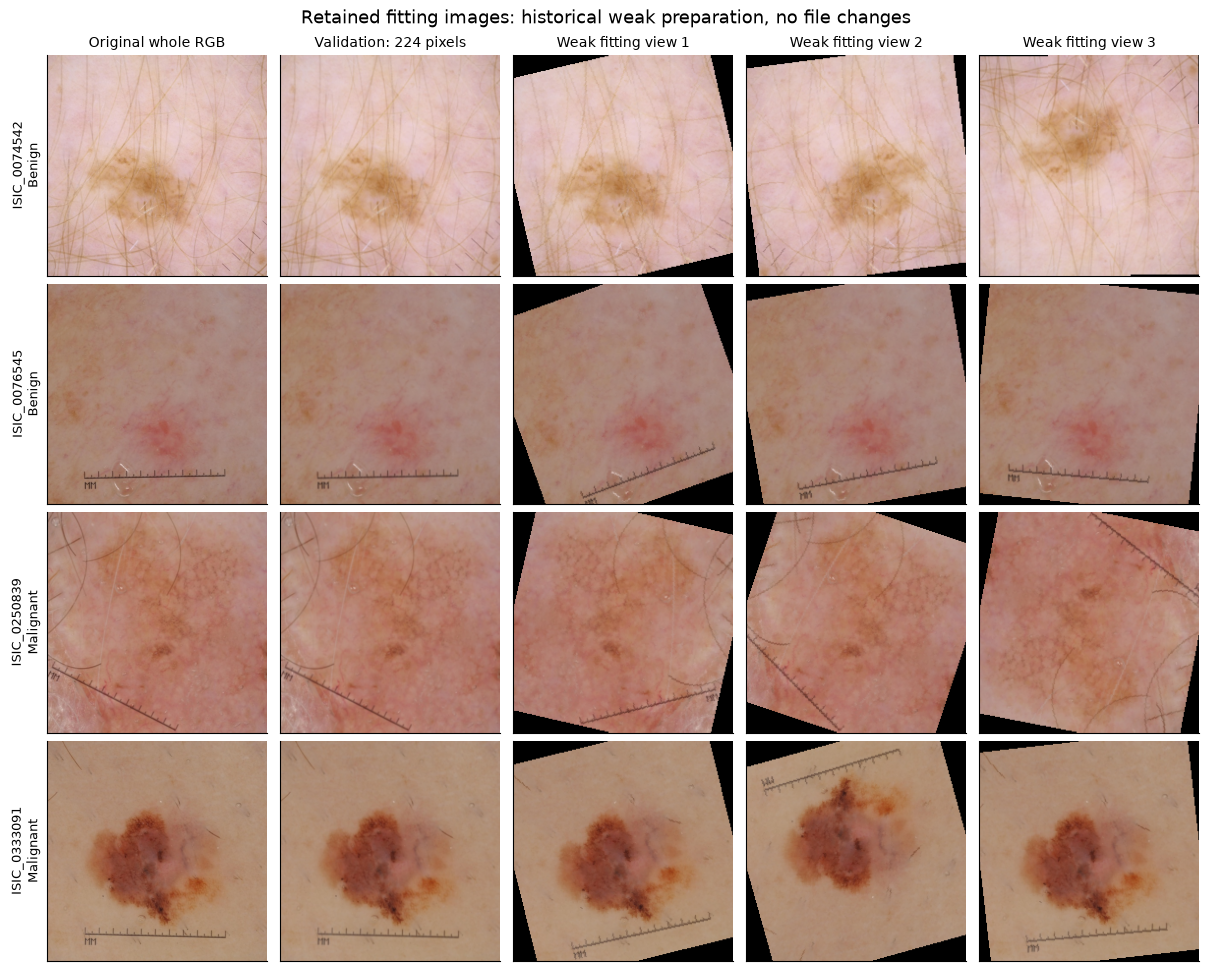

Colour is displayed after reversing ImageNet normalisation. Weak rotation can leave black corners or clip framing; these previews document the preserved transform and do not approve a new augmentation profile.

In [3]:
image_docs.show_preparation(ROOT, data, dataset_identity, finish_figure)

## Nested selection and computing cost

Within each outer-training pool, screen four learning-rate/weighting recipes for six epochs on inner fold 0. Confirm the selected recipe to 12 epochs across three preserved inner patient folds. Take the median of three AP-best epochs, then freshly refit every outer-training patient for that fixed duration. Only then predict the held-out outer group. Square-root weights use deduplicated fitting class counts. Thirty-five raw fits measure this bounded procedure; 15 additional fits support training-only calibration.

,outer_fold,outer_images,outer_malignant_images,selected_recipe,inner_best_epochs,fresh_outer_refit_epochs,outer_status
0,0,1344,24,lr1e4_none,"[7, 11, 11]",11,complete
1,1,1366,26,lr1e4_none,"[9, 12, 7]",9,complete
2,2,1328,26,lr1e4_none,"[4, 3, 12]",4,complete
3,3,1371,25,lr1e4_none,"[8, 9, 10]",9,complete
4,4,1297,26,lr1e4_none,"[4, 9, 8]",8,complete


,outer_fold,recipe,screen_epochs_available,best_screen_epoch,screen_AP,screen_AUC,scope
0,0,lr1e4_none,6,4,0.148514,0.860751,inner selection diagnostic
1,0,lr1e4_sqrt,6,4,0.118139,0.860549,inner selection diagnostic
2,0,lr3e5_none,6,4,0.138282,0.835209,inner selection diagnostic
3,0,lr3e5_sqrt,6,4,0.131890,0.855972,inner selection diagnostic
4,1,lr1e4_none,6,5,0.158030,0.821047,inner selection diagnostic
5,1,lr1e4_sqrt,6,6,0.150037,0.806697,inner selection diagnostic
6,1,lr3e5_none,6,6,0.149604,0.842220,inner selection diagnostic
7,1,lr3e5_sqrt,6,6,0.134236,0.836821,inner selection diagnostic
8,2,lr1e4_none,6,4,0.210262,0.812835,inner selection diagnostic
9,2,lr1e4_sqrt,6,5,0.129671,0.825605,inner selection diagnostic


,outer_fold,recipe,inner_fold,epochs,status,training_minutes,peak_GPU_GiB
0,0,lr1e4_none,0,12,complete,7.613925,2.812526
1,0,lr1e4_none,1,12,complete,8.133338,2.812526
2,0,lr1e4_none,2,12,complete,6.767769,2.812526
3,0,lr1e4_sqrt,0,6,complete,3.819540,2.812526
4,0,lr3e5_none,0,6,complete,4.188335,2.813129
5,0,lr3e5_sqrt,0,6,complete,3.877970,2.812526
6,1,lr1e4_none,0,12,complete,7.072982,2.812526
7,1,lr1e4_none,1,12,complete,7.600634,2.812526
8,1,lr1e4_none,2,12,complete,7.404213,2.812526
9,1,lr1e4_sqrt,0,6,complete,3.139322,2.812526


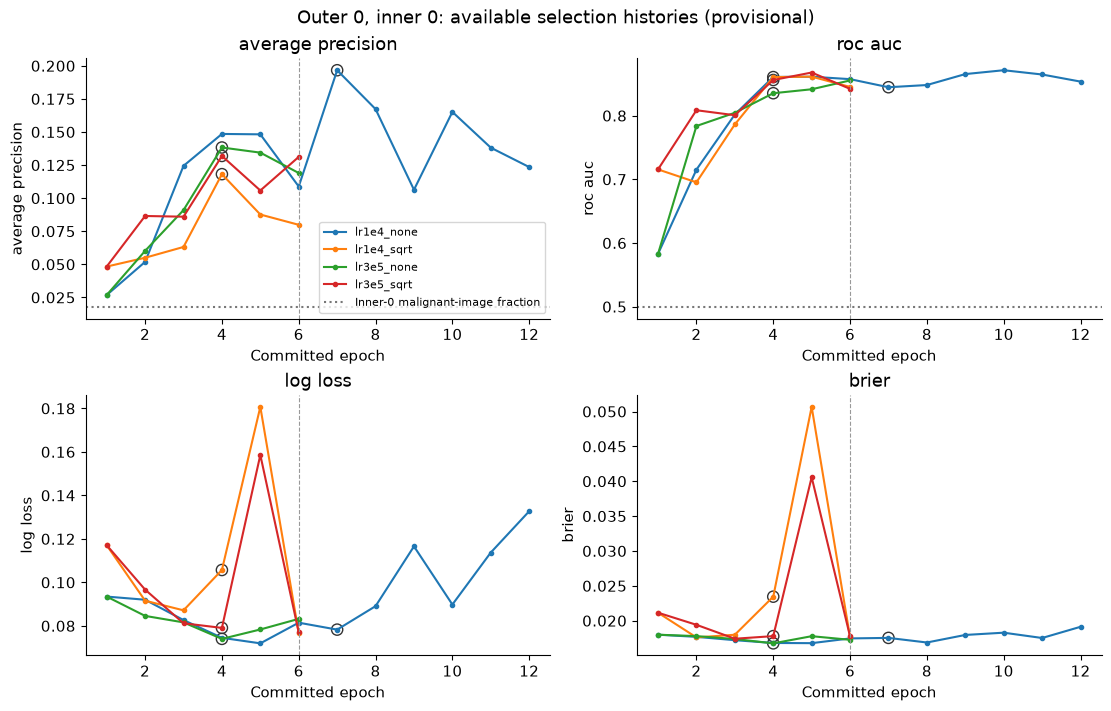

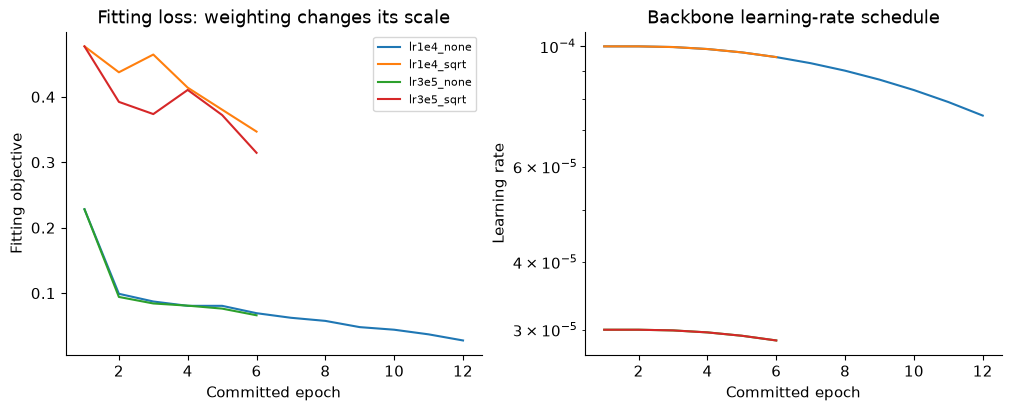

In [4]:
image_docs.image_progress(ROOT, data, dataset_identity, finish_figure)

## Read the inner learning curves

AP and ROC-AUC are higher-is-better ranking measures; log loss and Brier are lower-is-better score errors. Hollow rings mark AP-selected epochs across every panel. The vertical guide marks the six-epoch screen. Histories can be displayed before full OOF completion, so they are explicitly provisional selection diagnostics. The AP reference is the malignant-image fraction in this preserved inner-validation fold. Weighted fitting-loss scales cannot rank recipes against each other.

In [5]:
display(Markdown("The saved selection table, committed histories and measured minutes above explain each fold’s procedure; unfinished fold outcomes remain pending."))

The saved selection table, committed histories and measured minutes above explain each fold’s procedure; unfinished fold outcomes remain pending.

## Verify raw and calibration completion

A completed fold is not a completed five-fold experiment. Strict loaders check dataset identity, prediction coverage and hashes before final figures. Reporting-pending and training-pending are shown separately; no historical predictions fill an unfinished clean fold.

In [6]:
from melanoma_detection.image_nested_calibration_reporting import load_saved_calibration_run
raw = load_image_report(ROOT)
calibration = load_saved_calibration_run(ROOT, "b0_nested_calibration_dedup_v1")
display(pd.DataFrame([{ "stage": "raw B0", "status": raw["status"], "complete": raw["complete"]}, {"stage": "image calibration", "status": calibration["status"], "complete": calibration["complete"]}]))

,stage,status,complete
0,raw B0,complete,True
1,image calibration,complete,True


## Outer-fold ranking, ROC and precision–recall

Unweighted mean-fold AP is primary because malignant images are rare. Each bar uses independent held-out patients within this run; five-fold spread is descriptive variability, not a confidence interval. ROC plots recall against false alarms; PR plots precision against recall. The pooled curves are secondary because fold-specific models can have different score scales. Reliability bins compare mean score with observed melanoma frequency and show their support.

,fold,n_images,n_patients,n_positive,prevalence,average_precision,roc_auc,log_loss,brier
0,0,1344,84,24,0.017857,0.152537,0.854419,0.095513,0.022482
1,1,1366,84,26,0.019034,0.148876,0.839179,0.090245,0.019154
2,2,1328,87,26,0.019578,0.148730,0.864823,0.082345,0.018674
3,3,1371,82,25,0.018235,0.057262,0.757266,0.138206,0.018364
4,4,1297,85,26,0.020046,0.150444,0.838316,0.089270,0.019511


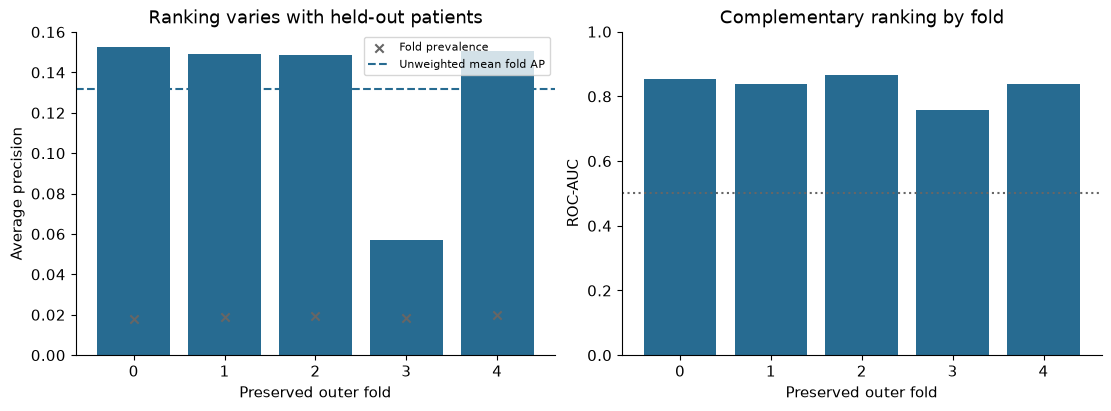

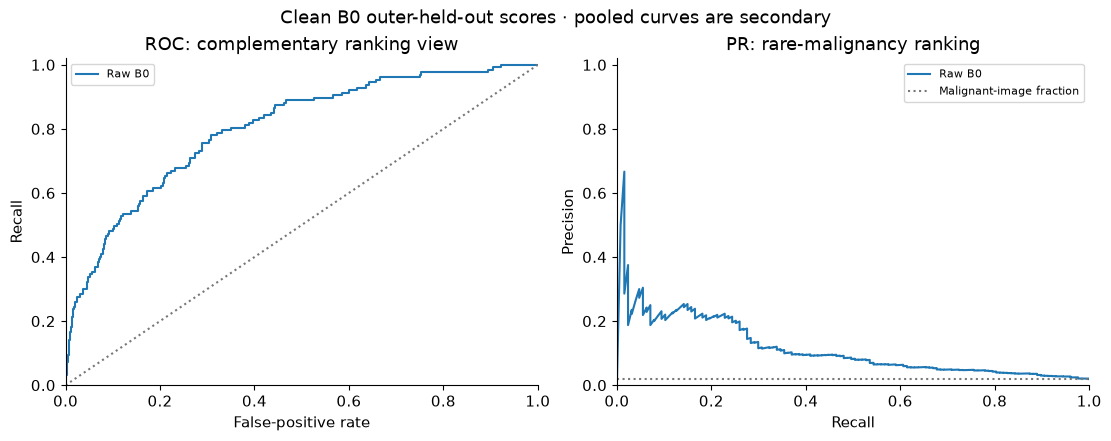

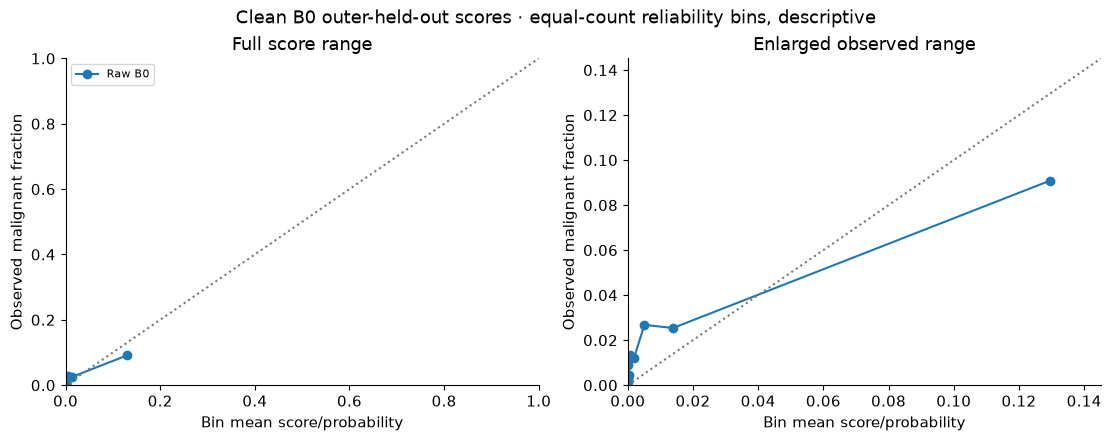

,bin,n_images,n_malignant_images,mean_probability,observed_rate,min_probability,max_probability,n_patients,model
0,1,671,2,0.000004,0.002981,2.590740e-09,0.000013,79,Raw B0
1,2,671,1,0.000031,0.001490,1.319787e-05,0.000050,154,Raw B0
2,3,670,2,0.000074,0.002985,4.980170e-05,0.000103,178,Raw B0
3,4,671,6,0.000145,0.008942,1.030144e-04,0.000201,192,Raw B0
4,5,670,3,0.000313,0.004478,2.014816e-04,0.000447,220,Raw B0
5,6,671,9,0.000721,0.013413,4.477781e-04,0.001118,241,Raw B0
6,7,670,8,0.001890,0.011940,1.118944e-03,0.003053,252,Raw B0
7,8,671,18,0.005082,0.026826,3.058046e-03,0.007783,259,Raw B0
8,9,670,17,0.013827,0.025373,7.784358e-03,0.022908,244,Raw B0
9,10,671,61,0.129615,0.090909,2.294426e-02,0.991087,223,Raw B0


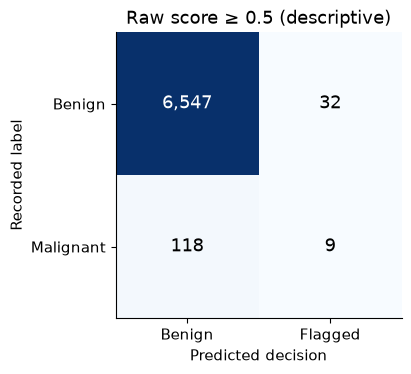

,scenario,TN,FP,FN,TP,recall,precision,specificity,flagged_images
0,Raw score ≥ 0.5 (descriptive),6547,32,118,9,0.070866,0.219512,0.995136,41


In [7]:
image_docs.raw_oof_figures(raw, finish_figure)

## Training-only calibration and frozen decisions

Three fresh fixed-duration fits per outer-training pool produce training-only OOF scores. Those scores fit the logistic-on-logits map and academic 80%-recall cutoffs. Outer patients never fit maps or cutoffs. Read confusion matrices by true-label rows and decision columns: FN are missed malignant images; FP are benign flags. The raw 0.5 cutoff is descriptive, while the training-selected scenarios use fold-specific frozen rules.

,fold,n_images,n_patients,n_positive,prevalence,average_precision,roc_auc,log_loss,brier,model
0,0,1344,84,24,0.017857,0.152537,0.854419,0.095513,0.022482,raw
1,1,1366,84,26,0.019034,0.148876,0.839179,0.090245,0.019154,raw
2,2,1328,87,26,0.019578,0.148730,0.864823,0.082345,0.018674,raw
3,3,1371,82,25,0.018235,0.057262,0.757266,0.138206,0.018364,raw
4,4,1297,85,26,0.020046,0.150444,0.838316,0.089270,0.019511,raw
5,0,1344,84,24,0.017857,0.152537,0.854419,0.090409,0.017738,calibrated
6,1,1366,84,26,0.019034,0.148876,0.839179,0.078001,0.017527,calibrated
7,2,1328,87,26,0.019578,0.148730,0.864823,0.076806,0.018044,calibrated
8,3,1371,82,25,0.018235,0.057262,0.757266,0.089645,0.017793,calibrated
9,4,1297,85,26,0.020046,0.150444,0.838316,0.087645,0.018813,calibrated


,fold,raw_average_precision,calibrated_average_precision,ap_difference,raw_roc_auc,calibrated_roc_auc,ap_invariant,roc_auc_invariant,changed_training_selected_decisions
0,0,0.152537,0.152537,0.000000e+00,0.854419,0.854419,True,True,0
1,1,0.148876,0.148876,0.000000e+00,0.839179,0.839179,True,True,0
2,2,0.148730,0.148730,0.000000e+00,0.864823,0.864823,True,True,0
3,3,0.057262,0.057262,-6.938894e-18,0.757266,0.757266,True,True,0
4,4,0.150444,0.150444,0.000000e+00,0.838316,0.838316,True,True,0


,fold,model,n_images,n_patients,n_positive,training_target_recall,threshold,threshold_scope,TP,FP,TN,FN,sensitivity,specificity,precision,flagged_fraction,recall,f1
0,0,raw,1344,84,24,0.8,0.000056,fixed per outer fold from training-only OOF sc...,24,1207,113,0,1.000000,0.085606,0.019496,0.915923,1.000000,0.038247
1,0,calibrated,1344,84,24,0.8,0.016348,fixed per outer fold from training-only OOF sc...,24,1207,113,0,1.000000,0.085606,0.019496,0.915923,1.000000,0.038247
2,1,raw,1366,84,26,0.8,0.002104,fixed per outer fold from training-only OOF sc...,24,490,850,2,0.923077,0.634328,0.046693,0.376281,0.923077,0.088889
3,1,calibrated,1366,84,26,0.8,0.017208,fixed per outer fold from training-only OOF sc...,24,490,850,2,0.923077,0.634328,0.046693,0.376281,0.923077,0.088889
4,2,raw,1328,87,26,0.8,0.006221,fixed per outer fold from training-only OOF sc...,22,336,966,4,0.846154,0.741935,0.061453,0.269578,0.846154,0.114583
5,2,calibrated,1328,87,26,0.8,0.015723,fixed per outer fold from training-only OOF sc...,22,336,966,4,0.846154,0.741935,0.061453,0.269578,0.846154,0.114583
6,3,raw,1371,82,25,0.8,0.001956,fixed per outer fold from training-only OOF sc...,7,148,1198,18,0.280000,0.890045,0.045161,0.113056,0.280000,0.077778
7,3,calibrated,1371,82,25,0.8,0.018041,fixed per outer fold from training-only OOF sc...,7,148,1198,18,0.280000,0.890045,0.045161,0.113056,0.280000,0.077778
8,4,raw,1297,85,26,0.8,0.000228,fixed per outer fold from training-only OOF sc...,25,838,433,1,0.961538,0.340677,0.028969,0.665382,0.961538,0.056243
9,4,calibrated,1297,85,26,0.8,0.015263,fixed per outer fold from training-only OOF sc...,25,838,433,1,0.961538,0.340677,0.028969,0.665382,0.961538,0.056243


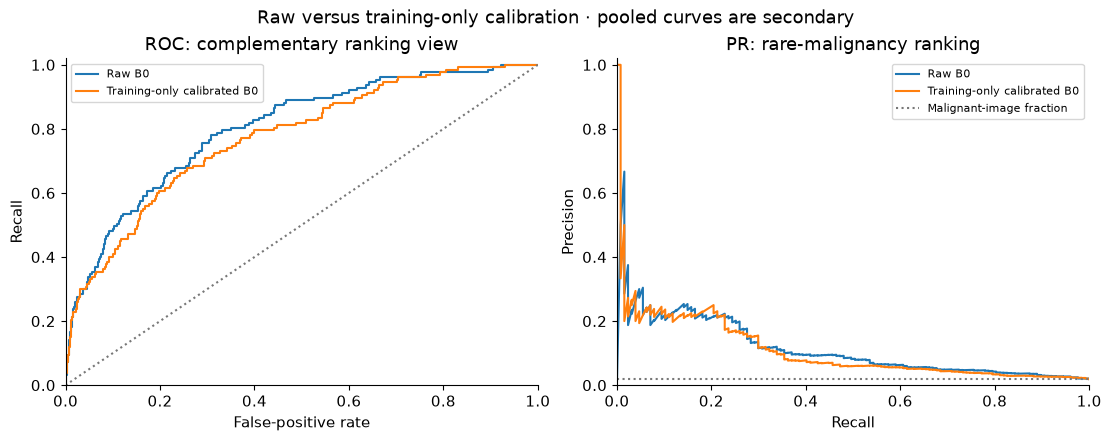

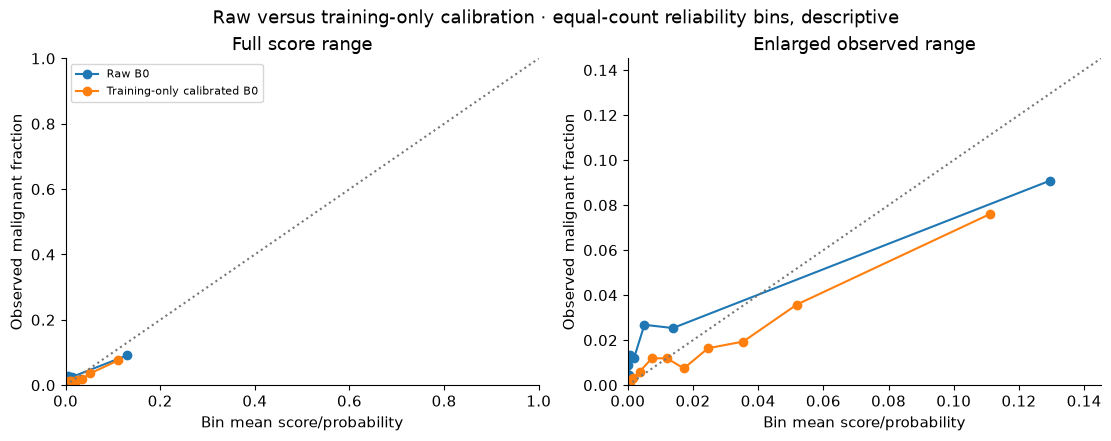

,bin,n_images,n_malignant_images,mean_probability,observed_rate,min_probability,max_probability,n_patients,model
0,1,671,2,0.000004,0.002981,2.590740e-09,0.000013,79,Raw B0
1,2,671,1,0.000031,0.001490,1.319787e-05,0.000050,154,Raw B0
2,3,670,2,0.000074,0.002985,4.980170e-05,0.000103,178,Raw B0
3,4,671,6,0.000145,0.008942,1.030144e-04,0.000201,192,Raw B0
4,5,670,3,0.000313,0.004478,2.014816e-04,0.000447,220,Raw B0
5,6,671,9,0.000721,0.013413,4.477781e-04,0.001118,241,Raw B0
6,7,670,8,0.001890,0.011940,1.118944e-03,0.003053,252,Raw B0
7,8,671,18,0.005082,0.026826,3.058046e-03,0.007783,259,Raw B0
8,9,670,17,0.013827,0.025373,7.784358e-03,0.022908,244,Raw B0
9,10,671,61,0.129615,0.090909,2.294426e-02,0.991087,223,Raw B0


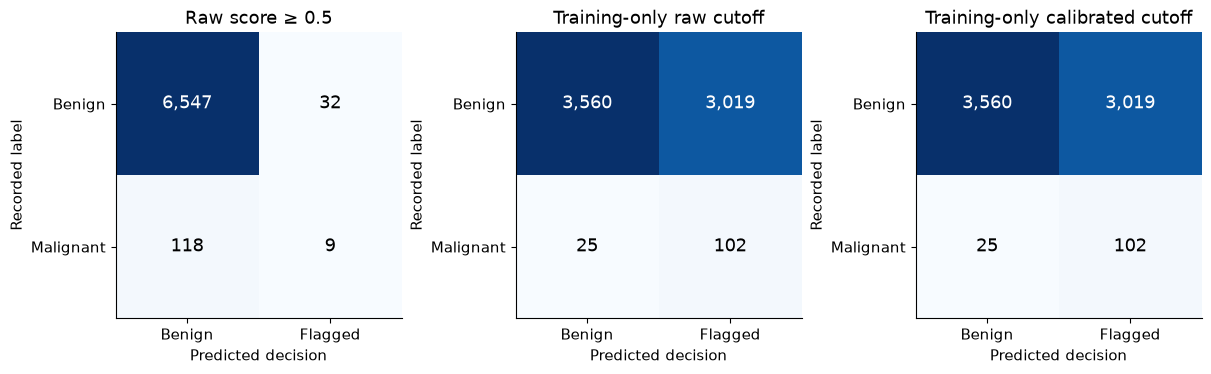

,scenario,TN,FP,FN,TP,recall,precision,specificity,flagged_images
0,Raw score ≥ 0.5,6547,32,118,9,0.070866,0.219512,0.995136,41
1,Training-only raw cutoff,3560,3019,25,102,0.803150,0.032682,0.541116,3121
2,Training-only calibrated cutoff,3560,3019,25,102,0.803150,0.032682,0.541116,3121


A monotonic map preserves within-fold ranking. Different fold-specific maps can change pooled ordering. Calibration is assessed with log loss, Brier and reliability; the academic training-only 80%-recall rule does not guarantee 80% recall on held-out patients.

In [8]:
image_docs.calibration_figures(calibration, finish_figure)

## Matched clean metadata comparison

B0, fixed spline and the three-seed NN mean must cover exactly the same retained image IDs and patients. AP is the predeclared ranking objective; probability and cutoff measures address different questions. Prior development exploration remains a limitation, and a patient bootstrap conditions on saved fits rather than repeating training.

,population,model,aggregation,fold,weighting,n_images,n_patients,n_malignant_images,n_malignant_patients,average_precision,roc_auc,log_loss,brier,role
7,clean,b0_raw,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.131570,0.830801,0.099116,0.019637,predeclared
10,clean,metadata_nn_mean,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.059570,0.676694,0.090169,0.018382,predeclared
17,clean,spline_raw,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.064842,0.655631,0.091006,0.018422,predeclared


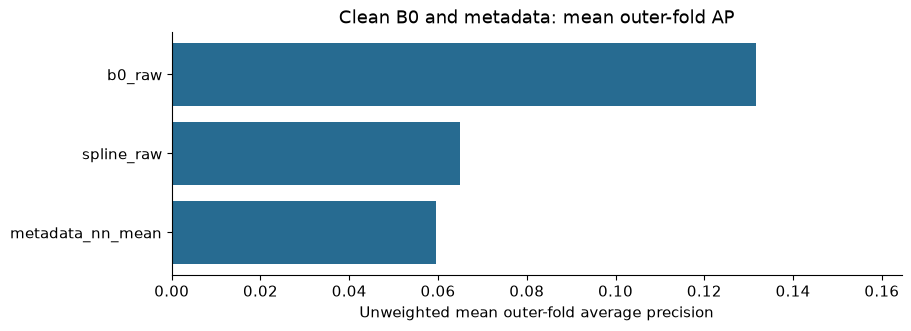

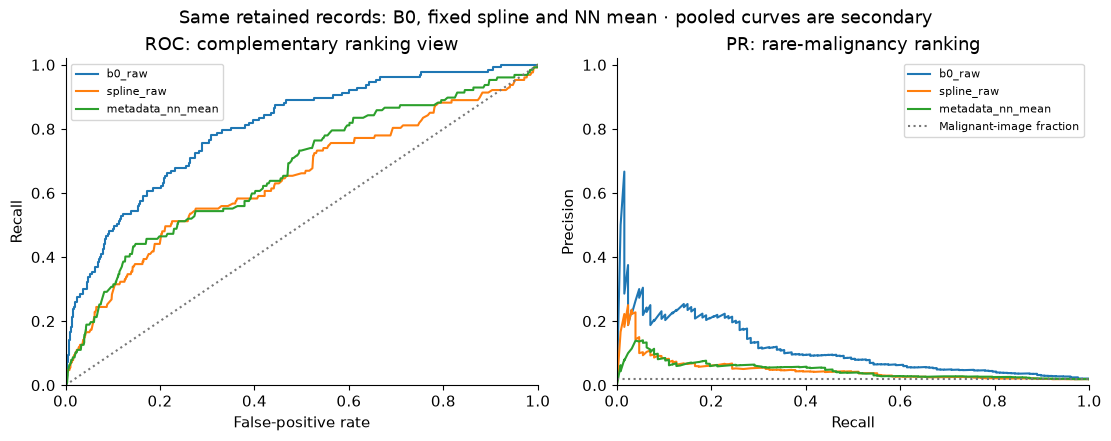

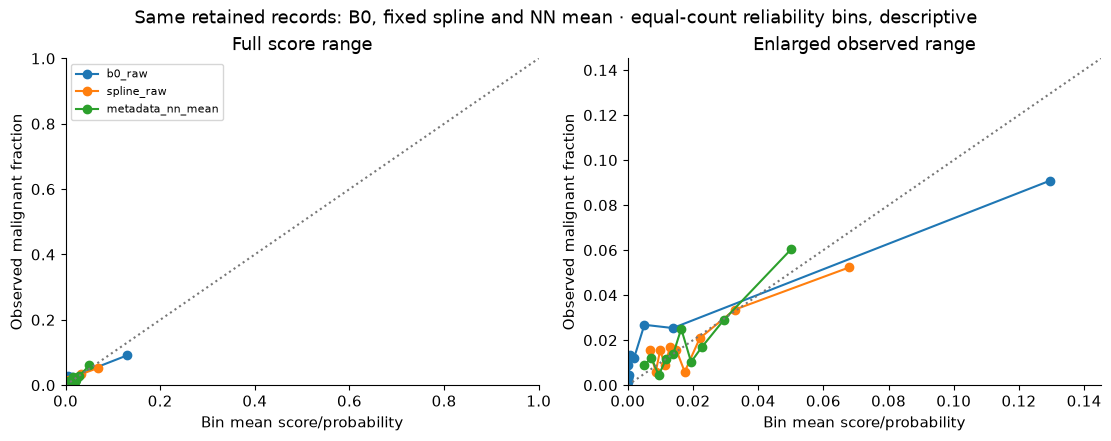

,bin,n_images,n_malignant_images,mean_probability,observed_rate,min_probability,max_probability,n_patients,model
0,1,671,2,0.000004,0.002981,2.590740e-09,0.000013,79,b0_raw
1,2,671,1,0.000031,0.001490,1.319787e-05,0.000050,154,b0_raw
2,3,670,2,0.000074,0.002985,4.980170e-05,0.000103,178,b0_raw
3,4,671,6,0.000145,0.008942,1.030144e-04,0.000201,192,b0_raw
4,5,670,3,0.000313,0.004478,2.014816e-04,0.000447,220,b0_raw
5,6,671,9,0.000721,0.013413,4.477781e-04,0.001118,241,b0_raw
6,7,670,8,0.001890,0.011940,1.118944e-03,0.003053,252,b0_raw
7,8,671,18,0.005082,0.026826,3.058046e-03,0.007783,259,b0_raw
8,9,670,17,0.013827,0.025373,7.784358e-03,0.022908,244,b0_raw
9,10,671,61,0.129615,0.090909,2.294426e-02,0.991087,223,b0_raw


In [9]:
table = comparison_table()
selected = table[table.model.isin(["b0_raw", "metadata_nn_mean", "spline_raw"])] if not table.empty else table
display(selected)
model_chart(selected, "Clean B0 and metadata: mean outer-fold AP")
image_docs.matched_comparator_figures(score_bundle(), finish_figure)

## Interpretation boundary

These are development results. Patient grouping protects separation between fitting and validation; bootstrap intervals condition on saved models. Sparse subgroups and selected inner-validation pilots cannot establish a final winner. No reserved-test conclusion is made.